# Predicting House Prices with Linear Regression
Oasis Infobyte Internship | Data Analytics | Level 2, Task 1

## 1. Setup
Google Drive is connected so the notebook can read the dataset, and the libraries needed for the analysis are imported.

In [38]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Loading and Inspecting the Data
The dataset is loaded and its size, structure and first rows are checked.

In [40]:
df = pd.read_csv("/content/drive/MyDrive/train.csv")
df.shape

(1460, 81)

In [41]:
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [42]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

## 3. Checking for Missing Values and Duplicates
The 10 columns with the most missing values are listed, and the data is checked for duplicate rows. In this dataset, a blank in some columns (such as PoolQC) means the feature does not exist, for example no pool, rather than an error.

In [43]:
df.isnull().sum().sort_values(ascending=False).head(10)

,0
PoolQC,1453
MiscFeature,1406
Alley,1369
Fence,1179
MasVnrType,872
FireplaceQu,690
LotFrontage,259
GarageQual,81
GarageFinish,81
GarageType,81


In [44]:
df.duplicated().sum()

np.int64(0)

## 4. The Target Variable: Sale Price
The target is the value the model will learn to predict. Its summary statistics, distribution and skewness are examined first.

In [45]:
df["SalePrice"].describe()

,SalePrice
count,1460.000000
mean,180921.195890
std,79442.502883
min,34900.000000
25%,129975.000000
50%,163000.000000
75%,214000.000000
max,755000.000000


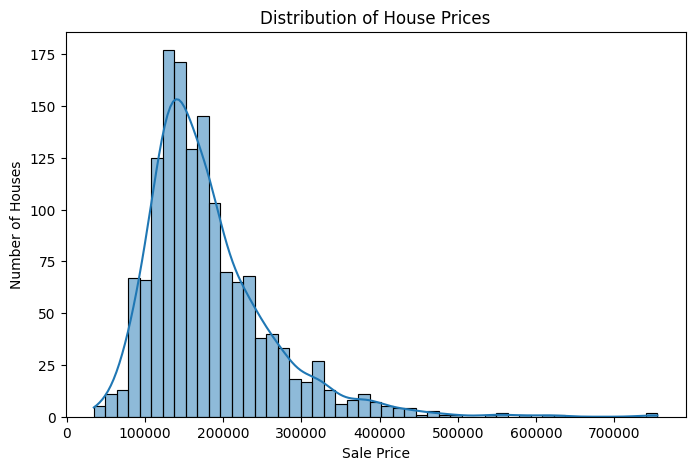

In [46]:
plt.figure(figsize=(8, 5))
sns.histplot(df["SalePrice"], kde=True)
plt.title("Distribution of House Prices")
plt.xlabel("Sale Price")
plt.ylabel("Number of Houses")
plt.show()

In [47]:
df["SalePrice"].skew()

np.float64(1.8828757597682129)

**Observations:** The dataset contains 1,460 houses with no duplicate rows. Several columns have many blanks (PoolQC, MiscFeature, Alley, Fence, MasVnrType), but in this dataset a blank usually means the feature does not exist (for example, no pool or no veneer), not that data is missing. The target, SalePrice, is right-skewed (skewness 1.88): the mean (180,921) is above the median (163,000) because a small number of expensive houses, up to 755,000, pull the average up. This may affect how evenly the model's errors are spread, so the residuals will be checked later.

## 5. Feature Selection
Out of 81 columns, 12 were chosen as likely predictors of house price, based on what typically drives property values:

**Size and space**
- GrLivArea: above-ground living area. Larger homes sell for more.
- TotalBsmtSF: total basement area, which adds usable space.
- LotArea and LotFrontage: the size of the plot and its street frontage.
- BedroomAbvGr and FullBath: bedrooms and bathrooms, which buyers look for.
- GarageCars: garage capacity.

**Quality and condition**
- OverallQual: overall build and finish quality, rated 1 to 10.
- KitchenQual: kitchen quality, which strongly influences perceived value.
- CentralAir: whether the house has central air conditioning.

**Age**
- HouseAge: calculated as year sold minus year built. Newer homes usually sell for more.

**Location**
- Neighborhood: location is one of the biggest drivers of price.

Columns with mostly blanks that actually mean "feature absent" (PoolQC, Alley, Fence, MiscFeature) were excluded.

In [48]:
df["HouseAge"] = df["YrSold"] - df["YearBuilt"]

In [49]:
selected = ["SalePrice", "GrLivArea", "OverallQual", "HouseAge", "TotalBsmtSF", "GarageCars",
            "FullBath", "BedroomAbvGr", "LotArea", "LotFrontage", "Neighborhood", "KitchenQual", "CentralAir"]
data = df[selected].copy()
data.shape

(1460, 13)

## 6. How Strongly Is Each Numeric Feature Related to Price?
Correlation with SalePrice is calculated for each numeric feature. Values range from -1 to +1: close to +1 means price rises as the feature rises, close to -1 means price falls as the feature rises, and close to 0 means little linear relationship.

In [50]:
data.corr(numeric_only=True)["SalePrice"].sort_values(ascending=False)

,SalePrice
SalePrice,1.000000
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
TotalBsmtSF,0.613581
FullBath,0.560664
LotFrontage,0.351799
LotArea,0.263843
BedroomAbvGr,0.168213
HouseAge,-0.523350


## 7. Handling Missing Values
Only LotFrontage has missing values among the selected features (259 blanks, about 18%). Dropping them would discard many valid houses, so the blanks are filled with the median. The median is used instead of the mean because it is not pulled by unusually large plots.

In [51]:
data.isnull().sum()

,0
SalePrice,0
GrLivArea,0
OverallQual,0
HouseAge,0
TotalBsmtSF,0
GarageCars,0
FullBath,0
BedroomAbvGr,0
LotArea,0
LotFrontage,259


In [52]:
median_frontage = data["LotFrontage"].median()
data["LotFrontage"] = data["LotFrontage"].fillna(median_frontage)

In [53]:
data.isnull().sum().sum()

np.int64(0)

## 8. Encoding Categorical Features (One-Hot Encoding)
Linear regression can only work with numbers, but Neighborhood, KitchenQual and CentralAir contain text categories. One-hot encoding turns each category into its own column holding 1 (yes) or 0 (no). One category per feature is dropped to avoid redundancy: it becomes the reference group that the others are compared against.

In [54]:
data_encoded = pd.get_dummies(data, drop_first=True, dtype=int)
data_encoded.shape

(1460, 38)

In [55]:
data_encoded.head()

,SalePrice,GrLivArea,OverallQual,HouseAge,TotalBsmtSF,GarageCars,FullBath,BedroomAbvGr,LotArea,LotFrontage,...,Neighborhood_Sawyer,Neighborhood_SawyerW,Neighborhood_Somerst,Neighborhood_StoneBr,Neighborhood_Timber,Neighborhood_Veenker,KitchenQual_Fa,KitchenQual_Gd,KitchenQual_TA,CentralAir_Y
0,208500,1710,7,5,856,2,2,3,8450,65.0,...,0,0,0,0,0,0,0,1,0,1
1,181500,1262,6,31,1262,2,2,3,9600,80.0,...,0,0,0,0,0,1,0,0,1,1
2,223500,1786,7,7,920,2,2,3,11250,68.0,...,0,0,0,0,0,0,0,1,0,1
3,140000,1717,7,91,756,3,1,3,9550,60.0,...,0,0,0,0,0,0,0,1,0,1
4,250000,2198,8,8,1145,3,2,4,14260,84.0,...,0,0,0,0,0,0,0,1,0,1


## 9. Correlation Heatmap
A heatmap of the numeric features and SalePrice shows which features are most strongly related to price, and whether any features overlap with each other. The encoded 0/1 columns are excluded, since correlations on them are less meaningful.

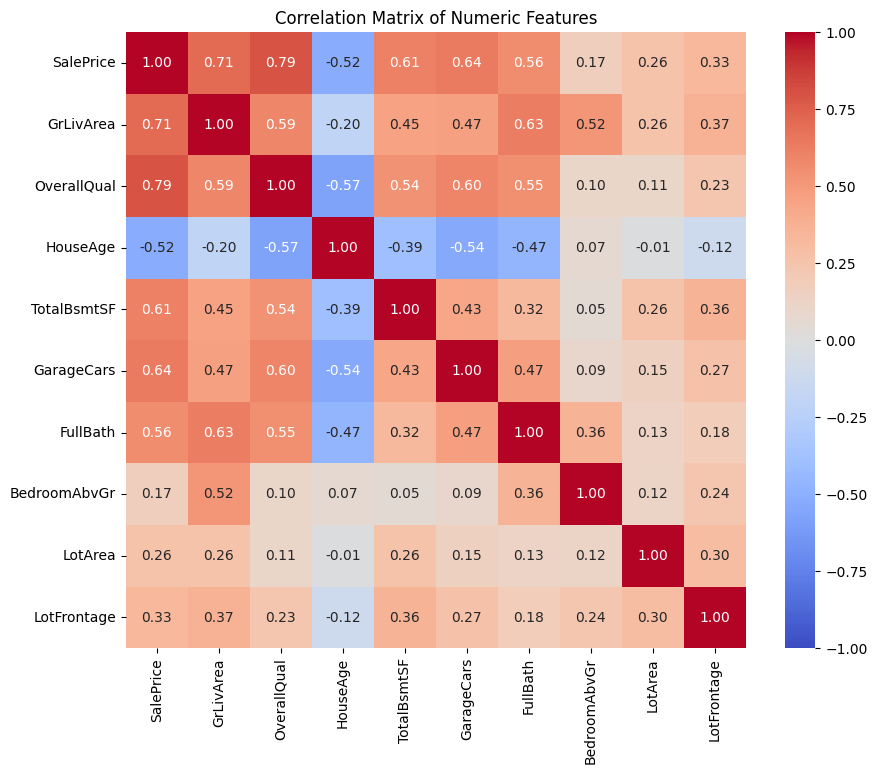

In [56]:
num_cols = ["SalePrice", "GrLivArea", "OverallQual", "HouseAge", "TotalBsmtSF",
            "GarageCars", "FullBath", "BedroomAbvGr", "LotArea", "LotFrontage"]
plt.figure(figsize=(10, 8))
sns.heatmap(data[num_cols].corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title("Correlation Matrix of Numeric Features")
plt.show()

**Observations:** OverallQual (0.79) and GrLivArea (0.71) are the features most strongly correlated with price, followed by GarageCars (0.64) and TotalBsmtSF (0.61). HouseAge has a negative correlation (-0.52), meaning older houses sell for less. BedroomAbvGr (0.17) and LotArea (0.26) have weak relationships with price. Some features are correlated with each other, such as GrLivArea and FullBath (0.63), so larger houses tend to also have more bathrooms and higher quality.

## 10. Splitting the Data into Training and Test Sets
80% of the houses are used to train the model, and 20% are kept back to test it.

In [57]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [58]:
X = data_encoded.drop(columns="SalePrice")
y = data_encoded["SalePrice"]

In [59]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(1168, 37) (292, 37)


## 11. Training the Linear Regression Model
The model studies the training houses and learns how much each feature (size, quality, age and so on) adds to or takes away from the price.

In [60]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

## 12. Making Predictions on the Test Set
The trained model estimates the price of each of the 292 houses it has never seen. These predictions are then compared with the real prices.

In [61]:
y_pred = model.predict(X_test)

In [62]:
comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred.round(0)
})
comparison["Difference"] = comparison["Predicted"] - comparison["Actual"]
comparison.head(5)

,Actual,Predicted,Difference
0,154500,136015.0,-18485.0
1,325000,322164.0,-2836.0
2,115000,114571.0,-429.0
3,159000,174423.0,15423.0
4,315500,308199.0,-7301.0


## 13. Evaluating the Model
The predictions are compared with the real prices using three measures:
- **MSE** (mean squared error): the average of the squared prediction errors. Large mistakes are penalised heavily.
- **RMSE** (root mean squared error): the square root of MSE, which puts the error back in price units.
- **R²**: the share of the variation in prices that the model explains, from 0 (nothing) to 1 (everything).

In [63]:
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MSE :", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R²  :", round(r2, 4))

MSE : 1186869434.17
RMSE: 34450.97
R²  : 0.8453


**Observations:** On the 292 unseen test houses, the model achieved an R² of about 0.85, meaning it explains roughly 85% of the variation in house prices. The RMSE of about 34,451 means predictions are typically off by around 34,000, compared with an average sale price of roughly 179,000.

## 14. Actual vs Predicted Prices
Each dot is one test house. The horizontal axis shows its real sale price and the vertical axis shows the price the model predicted. A perfect model would place every dot on the red diagonal line, so the closer the dots are to the line, the better the predictions.

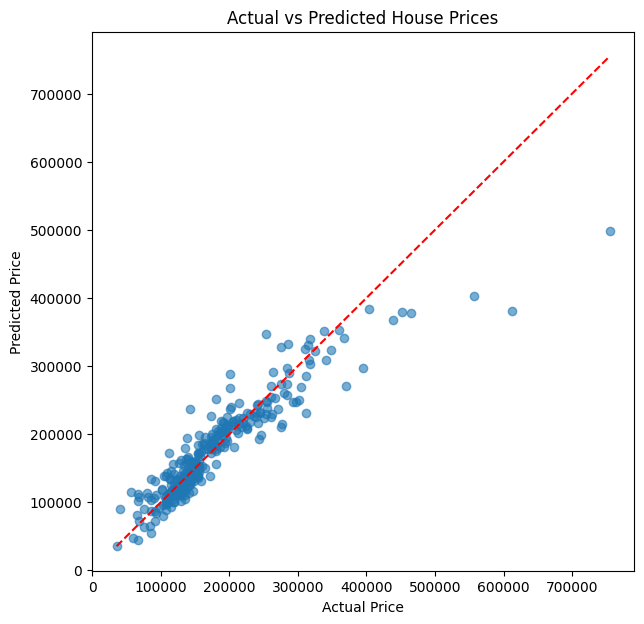

In [64]:
plt.figure(figsize=(7, 7))
plt.scatter(y_test, y_pred, alpha=0.6)

low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())
plt.plot([low, high], [low, high], color="red", linestyle="--")

plt.title("Actual vs Predicted House Prices")
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.show()

**Observations:** Most predictions lie close to the diagonal line, showing the model performs well for typical houses. At the high end the points fall below the line, meaning the model underestimates the most expensive houses. This is consistent with the right-skewed price distribution, because there are few expensive houses for the model to learn from.

## 15. Residual Analysis
A residual is the real price minus the predicted price. Plotting residuals against predicted prices shows whether the model's errors are random. In a good linear model, residuals scatter randomly around zero with no pattern. A visible pattern, such as errors growing larger for expensive houses, means the model is missing something systematic.

In [65]:
residuals = y_test - y_pred

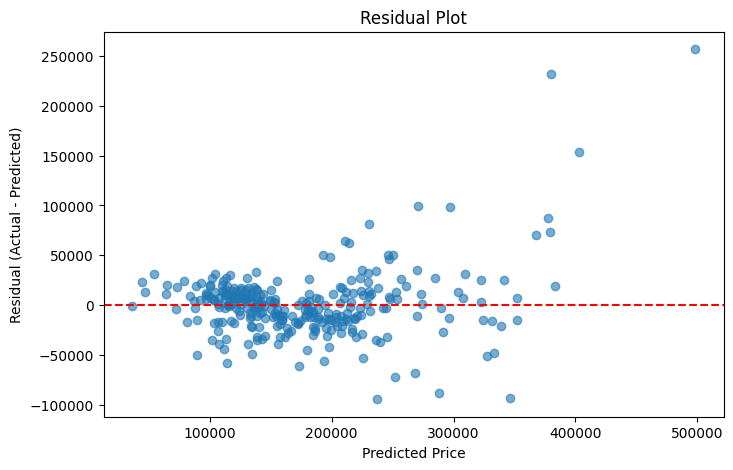

In [66]:
plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals, alpha=0.6)
plt.axhline(0, color="red", linestyle="--")
plt.title("Residual Plot")
plt.xlabel("Predicted Price")
plt.ylabel("Residual (Actual - Predicted)")
plt.show()

In [67]:
residuals.describe()

,SalePrice
count,292.000000
mean,1168.128921
std,34490.271223
min,-94284.165153
25%,-14550.520313
50%,871.812215
75%,12820.155567
max,256543.668577


**Observations:** The residuals are centred around zero (mean about 1,168), so the model is not systematically biased overall. However, the spread of the residuals widens as predicted price rises: typical errors are about 20,000 for houses predicted under 120,000, but about 85,000 for houses predicted above 300,000. The errors are therefore not evenly spread, which suggests a linear model on raw prices is less reliable for expensive houses. Predicting the log of price would be a possible improvement.

## 16. Coefficient Analysis
Each coefficient shows how much the predicted price changes when that feature increases by one unit, with all other features held constant. Positive coefficients raise the price and negative ones lower it. For one-hot encoded features, the coefficient is the price difference compared with the dropped reference category.

In [68]:
coefficients = pd.Series(model.coef_, index=X.columns).sort_values(ascending=False)
coefficients.head(8)

,0
Neighborhood_NoRidge,74732.998905
Neighborhood_StoneBr,62411.975603
Neighborhood_NridgHt,56433.967219
Neighborhood_Veenker,53136.592871
Neighborhood_Crawfor,45580.177890
Neighborhood_ClearCr,38025.723108
Neighborhood_Timber,26741.705442
Neighborhood_Somerst,26334.884867


In [69]:
coefficients.tail(8)

,0
LotFrontage,-32.432540
HouseAge,-221.845958
BedroomAbvGr,-3015.585087
Neighborhood_Blueste,-9582.937978
Neighborhood_BrDale,-12377.172553
KitchenQual_Gd,-45691.488275
KitchenQual_Fa,-48958.918446
KitchenQual_TA,-53886.917492


**Comparing numeric features fairly:** raw coefficients depend on each feature's units, so they cannot be compared directly. Multiplying each coefficient by the feature's standard deviation shows the effect on price of a typical change in that feature.

In [70]:
numeric = ["GrLivArea", "OverallQual", "HouseAge", "TotalBsmtSF", "GarageCars",
           "FullBath", "BedroomAbvGr", "LotArea", "LotFrontage"]
impact = (coefficients[numeric] * X_train[numeric].std()).sort_values(ascending=False)
impact.round(0)

,0
GrLivArea,23298.0
OverallQual,16993.0
GarageCars,8520.0
LotArea,6343.0
TotalBsmtSF,5952.0
FullBath,1535.0
LotFrontage,-729.0
BedroomAbvGr,-2427.0
HouseAge,-6811.0


**Observations:** Among numeric features, living area (GrLivArea) and overall quality (OverallQual) have the largest positive effect on price for a typical change, followed by garage capacity. House age has the largest negative effect. Neighbourhood and kitchen quality are also major drivers: relative to the reference categories, a house in NoRidge is worth about 74,700 more, and an excellent kitchen is worth about 46,000 to 54,000 more than other kitchen grades. The negative bedroom coefficient (about -3,000) is counter-intuitive but reflects the fact that, with living area held constant, extra bedrooms mean smaller rooms. Coefficients show association, not cause.

## 17. Bonus: Comparing Linear Regression with Ridge Regression
Ridge regression adds a penalty that shrinks large coefficients, which can reduce overfitting. Features are standardised first so the penalty treats them fairly. The Ridge model is trained on the same training data and evaluated on the same test houses, so the comparison is like for like.

In [71]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

In [72]:
ridge_model = make_pipeline(StandardScaler(), Ridge(alpha=10))
ridge_model.fit(X_train, y_train)
ridge_pred = ridge_model.predict(X_test)

In [73]:
ridge_rmse = np.sqrt(mean_squared_error(y_test, ridge_pred))
ridge_r2 = r2_score(y_test, ridge_pred)

model_comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Ridge Regression"],
    "RMSE": [rmse, ridge_rmse],
    "R2": [r2, ridge_r2]
}).round(4)
model_comparison

,Model,RMSE,R2
0,Linear Regression,34450.9715,0.8453
1,Ridge Regression,34447.3928,0.8453


**Observations:** Ridge regression (alpha = 10, with standardised features) achieved essentially the same performance as ordinary linear regression (R² about 0.845, RMSE about 34,450). Regularisation helps when a model overfits, but here the model performs as well on unseen data as on training data, so the added penalty brought no meaningful improvement. A stronger penalty (alpha = 100) slightly reduced accuracy. The linear model is therefore the preferred choice, since it is simpler and easier to interpret.

## 18. Checking for Overfitting
The model's score on the training houses is compared with its score on the unseen test houses. A much higher training score would suggest overfitting.

In [74]:
print("Training R²:", round(model.score(X_train, y_train), 4))
print("Test R²    :", round(model.score(X_test, y_test), 4))

Training R²: 0.8249
Test R²    : 0.8453


## 19. Conclusion

### Summary
A linear regression model was built to predict house sale prices from 1,460 houses in the Ames Housing dataset. Twelve likely predictors were selected from 81 columns (size, quality, age, garage, basement, lot, kitchen quality, air conditioning and neighbourhood). The only missing values among them (LotFrontage) were filled with the median, and the categorical features were one-hot encoded, giving 37 input features. The data was split 80/20 into training and test sets.

### Model Performance
On 292 unseen houses, the model achieved an R² of 0.845 and an RMSE of about 34,451. It explains roughly 85% of the variation in house prices, and its predictions are typically off by around 34,000, about one-fifth of the average sale price (roughly 179,000). Training and test scores were similar, so the model is not overfitting. Ridge regression gave practically identical results, so the simpler linear model was kept.

### What Drives Price
- **Size and quality:** living area and overall build quality have the largest positive effects among numeric features. A typical increase in living area adds about 23,300 and a typical increase in quality about 17,000.
- **Age:** older houses sell for less, at about 222 per year of age, and age has the largest negative effect among numeric features.
- **Location and kitchen:** neighbourhood is a major driver. Relative to the reference neighbourhood, a house in NoRidge is worth about 74,700 more. An excellent kitchen is worth roughly 46,000 to 54,000 more than other kitchen grades.
- **Bedrooms:** the coefficient is slightly negative (about -3,000 per bedroom). This is because living area is already in the model, so an extra bedroom means smaller rooms, not a less valuable house.

### Limitations
- The model underestimates expensive houses. For houses predicted above 300,000, typical errors are about 85,000, compared with about 20,000 for cheaper houses. The price distribution is right-skewed, and few expensive houses are available to learn from.
- Only 12 of 81 available features were used, and the model assumes straight-line relationships.
- The data comes from one city and period, so results may not apply elsewhere.
- Coefficients show association, not cause and effect.

### Possible Improvements
1. Predict the logarithm of price to reduce the skew and the widening errors.
2. Add more features, or interactions such as quality combined with size.
3. Compare with tree-based models such as Random Forest or Gradient Boosting.
4. Use cross-validation for a more reliable performance estimate.